In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.DataFrame({
    "Student":     ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics":  [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms":  [13, 15, 9, 17, 10, 14],
}).set_index("Student")
data

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


In [3]:
data.describe()

,Mathematics,Statistics,Programming,Algorithms
count,6.000000,6.000000,6.000000,6.00000
mean,12.666667,12.833333,13.666667,13.00000
std,3.326660,2.639444,3.011091,3.03315
min,8.000000,9.000000,10.000000,9.00000
25%,10.500000,11.250000,11.500000,10.75000
50%,13.000000,13.000000,13.500000,13.50000
75%,14.750000,14.750000,15.500000,14.75000
max,17.000000,16.000000,18.000000,17.00000


In [7]:
data_scaled = (data - data.mean()) / data.std()

data_scaled

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.200401,-0.694591,0.110702,0.000000
S2,0.701404,0.442012,0.774913,0.659380
S3,-1.402808,-1.452326,-1.217720,-1.318761
S4,1.302608,1.199747,1.439124,1.318761
S5,-0.801605,-0.315723,-0.885615,-0.989071
S6,0.400802,0.820880,-0.221404,0.329690


In [8]:
data_scaled.describe()

,Mathematics,Statistics,Programming,Algorithms
count,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00
mean,1.757853e-16,-2.220446e-16,1.711594e-16,9.251859e-18
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-1.402808e+00,-1.452326e+00,-1.217720e+00,-1.318761e+00
25%,-6.513039e-01,-5.998737e-01,-7.195621e-01,-7.418030e-01
50%,1.002006e-01,6.314460e-02,-5.535093e-02,1.648451e-01
75%,6.262538e-01,7.261629e-01,6.088602e-01,5.769579e-01
max,1.302608e+00,1.199747e+00,1.439124e+00,1.318761e+00


In [10]:
cov = data_scaled.cov()
cov

,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.000000,0.926291,0.945072,0.991055
Statistics,0.926291,1.000000,0.771721,0.874363
Programming,0.945072,0.771721,1.000000,0.963529
Algorithms,0.991055,0.874363,0.963529,1.000000


we notice from the covariance matrix that the have really strong correlation among them $>=0.77$.

In [11]:
eigenvalues, eigenvectors = np.linalg.eig(cov)
idx = np.argsort(eigenvalues)[::-1]
eigvals, eigvecs = eigenvalues[idx], eigenvectors[:, idx]
print("eigenvalues:")
print(eigvals.round(3))
print("-"*30)
print("eigenvectors:")
print(eigvecs.round(3))

eigenvalues:
[3.74e+00 2.40e-01 1.90e-02 1.00e-03]
------------------------------
eigenvectors:
[[ 0.517  0.032  0.209  0.83 ]
 [ 0.477  0.782 -0.315 -0.248]
 [ 0.493 -0.592 -0.625 -0.126]
 [ 0.512 -0.191  0.683 -0.484]]


In [13]:
PC = eigvecs[:,:2]
print("Principal components:")
PC.round(2)

Principal components:


array([[ 0.52,  0.03],
       [ 0.48,  0.78],
       [ 0.49, -0.59],
       [ 0.51, -0.19]])

In [14]:
project = data_scaled @ PC
print("the project of original scaled data on the PCs:")
project.round(2)

the project of original scaled data on the PCs:


,0,1
Student,,
S1,-0.38,-0.62
S2,1.29,-0.22
S3,-2.69,-0.21
S4,2.63,-0.12
S5,-1.51,0.44
S6,0.66,0.72


In [15]:
ratio = eigvals / eigvals.sum()
cum = np.cumsum(ratio)

print("the explained variance ratio:")
print(ratio.round(2))
print("-"*30)
print("the cumulative explained variance:")
print(cum.round(2))

the explained variance ratio:
[0.93 0.06 0.   0.  ]
------------------------------
the cumulative explained variance:
[0.93 0.99 1.   1.  ]


this last result of the cumulative explained variance means that the 2 pricipal components capture 99% of the variance.

# Using Predefined function

In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [17]:
scaler = StandardScaler()
data_ss = scaler.fit_transform(data)

In [19]:
pca = PCA(n_components=2)
data_trans = pca.fit_transform(data_ss)

In [20]:
print("Transformed data using PCA:")
print(data_trans.round(3))

Transformed data using PCA:
[[-0.417 -0.674]
 [ 1.416 -0.237]
 [-2.951 -0.228]
 [ 2.881 -0.136]
 [-1.652  0.483]
 [ 0.721  0.792]]


In [24]:
print("Principal components:")
print(pca.components_.T.round(3))
print("-"*30)
print("the explained variance ratio:")
print(pca.explained_variance_ratio_.round(2))

Principal components:
[[ 0.517  0.032]
 [ 0.477  0.782]
 [ 0.493 -0.592]
 [ 0.512 -0.191]]
------------------------------
the explained variance ratio:
[0.93 0.06]


In [25]:
print("difference between principal components:")
diff_pc = PC - pca.components_.T
diff_pc.round(3)

difference between principal components:


array([[-0.,  0.],
       [-0., -0.],
       [-0., -0.],
       [ 0., -0.]])

In [50]:
print("difference between data tranformed:")
diff = data_trans - project
diff.round(2)

difference between data tranformed:


,0,1
Student,,
S1,-0.04,-0.06
S2,0.12,-0.02
S3,-0.26,-0.02
S4,0.25,-0.01
S5,-0.14,0.04
S6,0.06,0.07


In [54]:
print(f"the percentage of the variance explained by the 2 first PCs: {cum[1].round(2)*100}%")

the percentage of the variance explained by the 2 first PCs: 99.0%


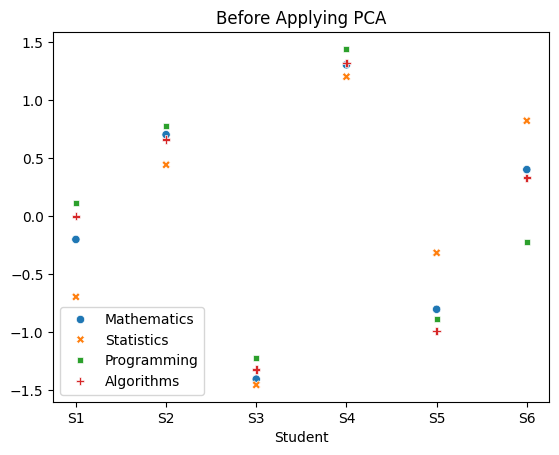

In [63]:
sns.scatterplot(data_scaled)
plt.title("Before Applying PCA")
plt.show()

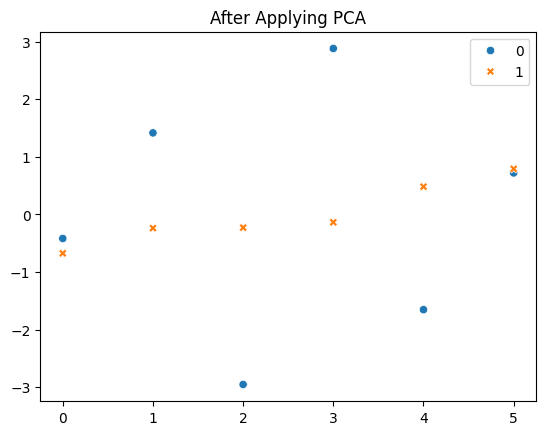

In [67]:
sns.scatterplot(data_trans)
plt.title("After Applying PCA")
plt.show()